<p align="center">
  <img src="assets/hero_kavram.svg" width="100%" alt="Gün 49 — XGBoost: Hatadan Öğrenen Ekip">
</p>

<p align="center">
  <img src="https://img.shields.io/badge/G%C3%BCn-49-7C3AED?style=for-the-badge" alt="Gün 49">
  <img src="https://img.shields.io/badge/Konu-XGBoost_(Kavram)-F6B84B?style=for-the-badge" alt="Konu">
  <img src="https://img.shields.io/badge/Seviye-Ba%C5%9Flang%C4%B1%C3%A7-16A34A?style=for-the-badge" alt="Seviye">
  <img src="https://img.shields.io/badge/XGBoost-0F172A?style=for-the-badge" alt="XGBoost">
  <img src="https://img.shields.io/badge/scikit--learn-F7931E?style=for-the-badge&logo=scikit-learn&logoColor=white" alt="scikit-learn">
</p>

<table>
<tr><td width="25%" valign="top" align="center"><h3>🌳</h3><b>Küçük ağaçlar</b><br><br>Tek büyük ağaç yerine<br>her biri <b>biraz</b> düzelten<br>yüzlerce küçük ağaç<br><br></td><td width="25%" valign="top" align="center"><h3>🧮</h3><b>Elle hesap</b><br><br>7 kişilik kredi örneğinde<br><b>her sayıyı</b> kendimiz<br>hesaplayıp doğruluyoruz<br><br></td><td width="25%" valign="top" align="center"><h3>🎞️</h3><b>Hareketli anlatım</b><br><br>Animasyonlarla<br><b>tur tur</b> öğrenen modeli<br>izliyoruz<br><br></td><td width="25%" valign="top" align="center"><h3>🧪</h3><b>Sıfırdan kod</b><br><br>40 satırda kendi<br>XGBoost'umuzu yazıp<br>kütüphaneyle karşılaştırıyoruz<br><br></td></tr>
</table>

<table><tr><td>

<img src="assets/etiket_hedef.svg" height="34" alt="Hedefler">

**Bu dersin sonunda şunları yapabiliyor olacaksınız:**

- 💡 XGBoost'un "hatadan öğrenen ekip" fikrini **kendi cümlelerinizle** anlatmak
- 🔁 Bir turun **beş adımını** (başlangıç → hata → ağaç → yaprak → güncelleme) sırasıyla açıklamak
- 🎯 **Log-odds** ve **sigmoid** ilişkisini bir örnek üzerinde hesaplamak
- ✂️ Bir bölünmenin **benzerlik (similarity)** ve **gain** değerini elle bulmak
- 🛡️ **λ, γ ve cover** düğmelerinin aşırı öğrenmeyi nasıl azalttığını göstermek
- 🏎️ Öğrenme hızı ile ağaç sayısı arasındaki dengeyi animasyonda yorumlamak
- 🧪 Kendi mini XGBoost'unuzun **gerçek kütüphaneyle aynı** sonucu verdiğini doğrulamak

</td></tr></table>

<p align="center">
  <img src="assets/yol_haritasi_kavram.svg" width="100%" alt="Ders yol haritası: 14 durak">
</p>

### 🧭 Hızlı Erişim

| Durak | Bölüm | Ana soru |
|:-:|:--|:--|
| 🧰 1 | [Kurulum](#p1) | Hangi araçlarla çalışıyoruz? |
| 💡 2 | [Büyük fikir](#p2) | XGBoost neden "hatadan öğrenen ekip"? |
| 🔁 3 | [Beş adımlık döngü](#p3) | Her tur tam olarak ne yapıyor? |
| 🎯 4 | [Başlangıç tahmini](#p4) | Log-odds ve sigmoid nedir? |
| 🧮 5 | [Hata (artık)](#p5) | Model nerede, ne kadar yanılıyor? |
| ✂️ 6 | [Bölünme ve gain](#p6) | Hangi soru veriyi en iyi ayırır? |
| 🍃 7 | [Yaprak ve güncelleme](#p7) | Ağaç tahmini nasıl düzeltir? |
| 📐 8 | [Gradyan ve Hessian](#p8) | Neden iki türev birden? |
| 🛡️ 9 | [Düzenleme](#p9) | λ, γ ve cover: akıllı budama |
| 🏎️ 10 | [Hız ve ağaç sayısı](#p10) | Öğrenme hızı nasıl yarışır? |
| 📈 11 | [Regresyon kardeşi](#p11) | Aynı mantık sayı tahmininde |
| 🌌 12 | [Gökyüzünde karar](#p12) | Karar sınırı tur tur büyüyor |
| 🧪 13 | [Sıfırdan XGBoost](#p13) | 40 satırda yeniden yazıp doğrula |
| 🎓 14 | [Aile ve özet](#p14) | Quiz, ödevler, kaynakça |

> 📎 Bu ders, **Atıl Samancıoğlu'nun XGBoost ders notundaki** (t.y.) 7 kişilik kredi örneğini ve adım sırasını izler; **tüm sayılar bu notebook'ta yeniden hesaplanıp gerçek `xgboost` kütüphanesiyle doğrulanır.** Ders notunun kendisi bu klasörde yayınlanmaz.

<a id="p1"></a>

<p align="center">
  <img src="assets/kavram_01.svg" width="100%" alt="Bölüm 1">
</p>

Kütüphaneleri, renk temasını ve iki küçük yardımcıyı (grafik kaydetme, **animasyon (GIF) kaydetme**) tek hücrede topluyoruz. `RANDOM_STATE` sabit olduğu için her çalıştırmada **aynı sonuçları** görürüz.

In [1]:
# ── Kütüphaneler ─────────────────────────────────────────────
import platform
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from IPython.display import Image, display
from matplotlib.animation import FuncAnimation, PillowWriter
from sklearn.datasets import make_classification, make_moons
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore")

# ── Sabitler ve klasörler ───────────────────────────────────
RANDOM_STATE = 42
FIG_DIR = Path("outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ── Görsel tema (notebook boyunca aynı renkler) ──────────────
RENK = {"altin": "#EDAE49", "mor": "#6C5CE7", "pembe": "#D1495B", "mavi": "#2B6CB0",
        "yesil": "#2E9E6B", "turuncu": "#E8833A", "gri": "#8A94A6", "koyu": "#2E4057", "cyan": "#0E9AA7"}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})


def kaydet(fig, ad):
    """Grafiği outputs/figures altına PNG olarak kaydeder."""
    yol = FIG_DIR / f"{ad}.png"
    fig.savefig(yol)
    print(f"💾 Kaydedildi → {yol.as_posix()}")


def gif_kaydet(kare_ciz, n_kare, yol, figsize=(7, 4), fps=6, dpi=75):
    """kare_ciz(fig, i) fonksiyonuyla her kareyi çizip animasyonlu GIF olarak kaydeder."""
    fig = plt.figure(figsize=figsize)
    anim = FuncAnimation(fig, lambda i: kare_ciz(fig, i), frames=n_kare)
    anim.save(yol, writer=PillowWriter(fps=fps), dpi=dpi)
    plt.close(fig)
    print(f"💾 Animasyon → {Path(yol).as_posix()} ({Path(yol).stat().st_size / 1024:.0f} KB)")


def sigmoid(z):
    """Log-odds'u (−∞..+∞) olasılığa (0..1) çevirir."""
    return 1.0 / (1.0 + np.exp(-z))


def logit(p):
    """Olasılığı log-odds'a çevirir: log(p / (1-p))."""
    return np.log(p / (1.0 - p))


print(f"Python {platform.python_version()} · XGBoost {xgboost.__version__} · scikit-learn {sklearn.__version__} · pandas {pd.__version__} · numpy {np.__version__}")

Python 3.13.18 · XGBoost 3.4.1 · scikit-learn 1.9.1 · pandas 3.0.5 · numpy 2.5.3


<a id="p2"></a>

<p align="center">
  <img src="assets/kavram_02.svg" width="100%" alt="Bölüm 2">
</p>

### 💡 2.1 · Usta ve Çıraklar

Bir kredi kartı başvurusunun onaylanıp onaylanmayacağını tahmin eden bir model düşünelim. **Tek bir kişiye** "karar ver" demek yerine bir **ekip** kuruyoruz:

1. **Usta**, herkese aynı genel tahmini yazar ("bu tür başvuruların %71'i onaylanıyor").
2. **Birinci çırak**, ustanın **en çok yanıldığı** başvurulara bakıp küçük bir düzeltme önerir.
3. **İkinci çırak**, şimdiye kadarki toplam tahminin **hâlâ yanlış kaldığı** yerleri düzeltir.
4. … Bu böyle sürer. Her çırak **küçük** bir iş yapar; ama hepsi toplanınca ortaya çok iyi bir karar çıkar.

İşte bu fikre **boosting** (güçlendirme) denir. **XGBoost** (*eXtreme Gradient Boosting*), bu fikrin **düzenli, hızlı ve titiz** uygulamasıdır.

<p align="center">
  <img src="assets/diyagram_takim.svg" width="100%" alt="Usta ve çıraklar">
</p>

💾 Kaydedildi → outputs/figures/kavram_01_tek_model_mi_ekip_mi.png


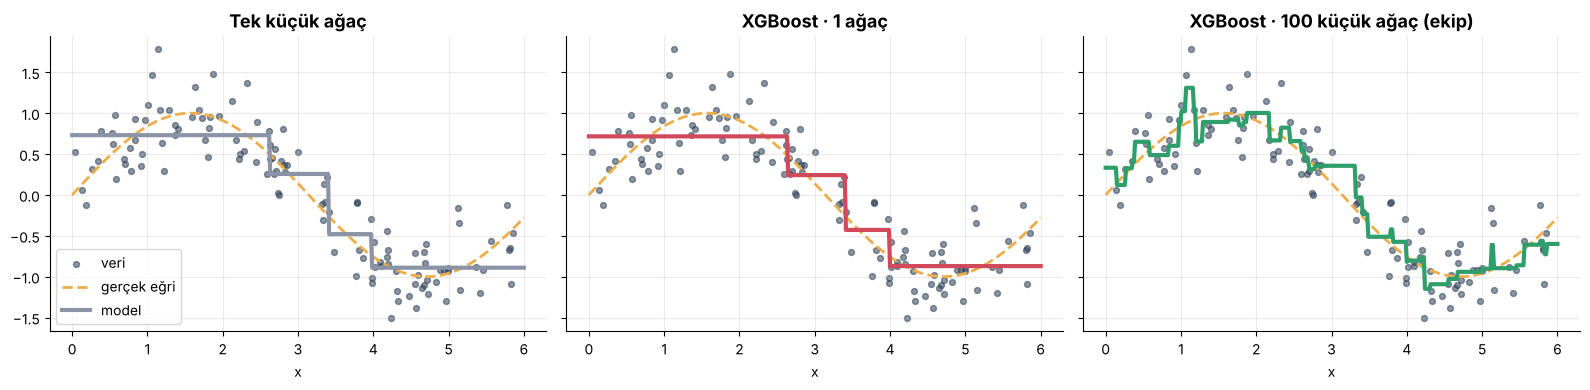

In [2]:
# Gürültülü bir eğri üzerinde: tek ağaç mı, 100 küçük ağaçlı ekip mi?
rng = np.random.default_rng(RANDOM_STATE)
x = np.sort(rng.uniform(0, 6, 120))
y = np.sin(x) + 0.3 * rng.normal(size=x.size)
Xg = x.reshape(-1, 1)
izgara = np.linspace(0, 6, 400).reshape(-1, 1)

tek_agac = DecisionTreeRegressor(max_depth=2, random_state=RANDOM_STATE).fit(Xg, y)
xgb_1 = XGBRegressor(n_estimators=1, max_depth=2, learning_rate=1.0, random_state=RANDOM_STATE).fit(Xg, y)
xgb_100 = XGBRegressor(n_estimators=100, max_depth=2, learning_rate=0.1, random_state=RANDOM_STATE).fit(Xg, y)

fig, eksen = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, model, ad, renk in zip(eksen, [tek_agac, xgb_1, xgb_100],
                                ["Tek küçük ağaç", "XGBoost · 1 ağaç", "XGBoost · 100 küçük ağaç (ekip)"],
                                [RENK["gri"], RENK["pembe"], RENK["yesil"]]):
    ax.scatter(x, y, s=18, color=RENK["koyu"], alpha=0.55, label="veri")
    ax.plot(izgara, np.sin(izgara), "--", color=RENK["altin"], lw=2, label="gerçek eğri")
    ax.plot(izgara, model.predict(izgara), color=renk, lw=3, label="model")
    ax.set_title(ad)
    ax.set_xlabel("x")
eksen[0].legend(loc="lower left")
fig.tight_layout()
kaydet(fig, "kavram_01_tek_model_mi_ekip_mi")
plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**Tek küçük ağaç** yalnızca birkaç basamaklı kaba bir tahmin yapar. **100 küçük ağaç**, her biri ötekinin eksiğini kapattığı için eğriyi yumuşak ve doğru biçimde yakalar. Ağaçların her biri tek başına **zayıftır**; gücü **ekip** verir.

</td></tr></table>

### 🧬 2.2 · Aile Ağacı: XGBoost Nereden Geliyor?

<p align="center">
  <img src="assets/diyagram_aile.svg" width="100%" alt="Topluluk ailesi">
</p>

Gradient Boosting fikri **Friedman (2001)** tarafından ortaya konmuştur; XGBoost ise bu fikri düzenleme, budama ve sistem optimizasyonlarıyla büyük veriye ölçekleyen yazılımdır (Chen ve Guestrin, 2016). Ders notunun giriş bölümü farkları şöyle sıralar:

<p align="center">
  <img src="assets/diyagram_xgb_farklari.svg" width="100%" alt="XGBoost'u farklı kılan beş parça">
</p>

> Bu derste bu beş parçanın **her birini** bir hesapla ya da deneyle göreceğiz.

<a id="p3"></a>

<p align="center">
  <img src="assets/kavram_03.svg" width="100%" alt="Bölüm 3">
</p>

XGBoost'un bir turu **hep aynı beş adımdan** oluşur. Bu diyagramı aklınızda tutarsanız dersin geri kalanı yalnızca "bu adımın içini açmaktır":

<p align="center">
  <img src="assets/diyagram_dongu.svg" width="100%" alt="Beş adımlık döngü">
</p>

| Adım | Ne yapılır? | Basit dille | Bölüm |
|:-:|:--|:--|:-:|
| **1** | Herkes için **aynı başlangıç tahmini** yazılır | "Henüz hiçbir şey bilmiyorum, ortalamayı söylüyorum" | [4](#p4) |
| **2** | Her örnek için **hata (artık)** hesaplanır | "Nerede ne kadar yanıldım?" | [5](#p5) |
| **3** | Hatayı en iyi ayıran **bölünme** seçilir (gain) | "Hataları gruplamak için en iyi soru hangisi?" | [6](#p6) |
| **4** | Her yaprağa bir **değer** verilir | "Bu gruptaki hatayı kapatmak için ne kadar düzeltmeliyim?" | [7](#p7) |
| **5** | Tahmin **küçük bir adımla** (öğrenme hızı) güncellenir | "Düzeltmeyi biraz uygula, başa dön" | [7](#p7) |

<a id="p4"></a>

<p align="center">
  <img src="assets/kavram_04.svg" width="100%" alt="Bölüm 4">
</p>

### 📋 4.1 · Örnek Veri: Kredi Kartı Onayı

Ders notundaki 7 kişilik veriyi kullanıyoruz: **Maaş** ve **Kredi skoru**'na bakıp **onay (1) / ret (0)** tahmin edeceğiz.

In [3]:
kredi = pd.DataFrame({
    "ID": range(1, 8),
    "Maaş (bin)": [30, 40, 50, 60, 70, 80, 90],
    "Kredi skoru": ["Düşük", "Düşük", "Orta", "Yüksek", "Orta", "Yüksek", "Yüksek"],
    "Onay": [0, 0, 1, 1, 1, 1, 1],
})
kredi["Skor (sayı)"] = kredi["Kredi skoru"].map({"Düşük": 1, "Orta": 2, "Yüksek": 3})   # ağaçlar için sıralı kodlama
display(kredi)

X_kredi = kredi[["Maaş (bin)", "Skor (sayı)"]].to_numpy(float)
y_kredi = kredi["Onay"].to_numpy(float)
print(f"Onaylı: {int(y_kredi.sum())} · Reddedilen: {int((1 - y_kredi).sum())}")

,ID,Maaş (bin),Kredi skoru,Onay,Skor (sayı)
0,1,30,Düşük,0,1
1,2,40,Düşük,0,1
2,3,50,Orta,1,2
3,4,60,Yüksek,1,3
4,5,70,Orta,1,2
5,6,80,Yüksek,1,3
6,7,90,Yüksek,1,3


Onaylı: 5 · Reddedilen: 2


### 🎲 4.2 · Başlangıç Tahmini: Log-Odds

Model henüz hiçbir özelliğe bakmadan **herkese aynı** tahmini yazar. Sınıflandırmada bu tahmin **log-odds** (olasılığın "oran"ının logaritması) biçiminde tutulur:

$$F_0 = \log\left(\frac{\text{onaylı sayısı}}{\text{reddedilen sayısı}}\right) = \log\left(\frac{5}{2}\right) \approx 0{,}916 \qquad\Rightarrow\qquad p = \frac{1}{1+e^{-F_0}} \approx 0{,}714$$

<p align="center">
  <img src="assets/diyagram_logodds.svg" width="100%" alt="Olasılık ve log-odds">
</p>

**Neden olasılığı doğrudan kullanmıyoruz?** Ağaçların küçük düzeltmeleri **toplanır**. Olasılık 0–1 arasında kalmak zorunda olduğu için toplama bozulabilir; log-odds ise **sınırsızdır**, toplamak güvenlidir. En sonda **sigmoid** ile tekrar olasılığa dönülür.

Onay oranı          : 5/7 = 0.7143
Başlangıç log-odds  : F0 = log(5/2) = 0.9163   (ders notu: ≈ 0.916)
Başlangıç olasılığı : p = 1/(1+e^-F0) = 0.7143   (ders notu: ≈ 0.714)


💾 Kaydedildi → outputs/figures/kavram_02_sigmoid.png


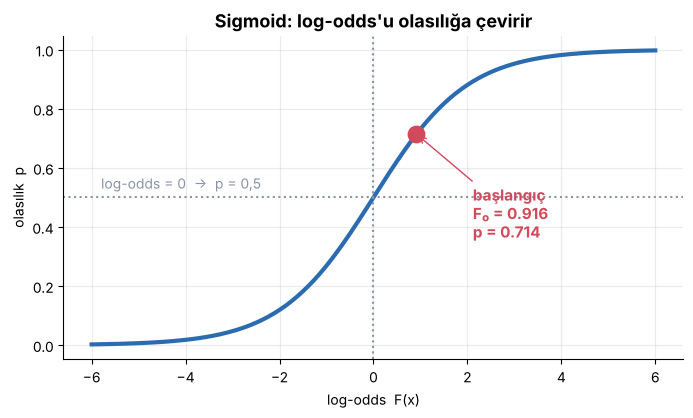

In [4]:
p_onay = y_kredi.mean()                       # 5/7
F0 = logit(p_onay)                            # başlangıç log-odds
p0 = sigmoid(F0)                              # sigmoid geri çevirir
print(f"Onay oranı          : 5/7 = {p_onay:.4f}")
print(f"Başlangıç log-odds  : F0 = log(5/2) = {F0:.4f}   (ders notu: ≈ 0.916)")
print(f"Başlangıç olasılığı : p = 1/(1+e^-F0) = {p0:.4f}   (ders notu: ≈ 0.714)")

# Sigmoid eğrisi: log-odds ↔ olasılık
z = np.linspace(-6, 6, 300)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(z, sigmoid(z), color=RENK["mavi"], lw=3)
ax.scatter([F0], [p0], s=140, color=RENK["pembe"], zorder=5)
ax.annotate(f"başlangıç\nF₀ = {F0:.3f}\np = {p0:.3f}", (F0, p0), xytext=(F0 + 1.2, p0 - 0.35), fontsize=11,
            arrowprops=dict(arrowstyle="->", color=RENK["pembe"]), color=RENK["pembe"], fontweight="bold")
ax.axhline(0.5, ls=":", color=RENK["gri"])
ax.axvline(0, ls=":", color=RENK["gri"])
ax.set(title="Sigmoid: log-odds'u olasılığa çevirir", xlabel="log-odds  F(x)", ylabel="olasılık  p")
ax.text(-5.8, 0.53, "log-odds = 0  →  p = 0,5", color=RENK["gri"])
kaydet(fig, "kavram_02_sigmoid")
plt.show()

<table><tr><td>

<img src="assets/etiket_kavram.svg" height="34" alt="Kavram">

**Log-odds** = olasılığın "oran"ının logaritması. **0** olduğunda olasılık tam **%50**'dir; pozitif olduğunda onay ihtimali yükselir, negatif olduğunda düşer. Ağaçlar log-odds'a **ekleme/çıkarma** yapar; son adımda sigmoid onu yeniden olasılığa çevirir.

</td></tr></table>

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

Ders notunda belirtildiği gibi, kayıp işlevi **log-loss** seçildiğinde klasik Gradient Boosting de log-odds ve sigmoid kullanır; bunlar yalnızca XGBoost'a özgü değildir. XGBoost bu süreci **sistemli, düzenli ve ikinci türevle** (bölüm 8) uygular.

</td></tr></table>

<a id="p5"></a>

<p align="center">
  <img src="assets/kavram_05.svg" width="100%" alt="Bölüm 5">
</p>

Başlangıç tahmini herkes için **0,714**. Gerçek etiket 0 ya da 1 olduğuna göre her kişinin **hatası (artığı)**:

$$R_i = Y_i - p_i$$

- **Negatif** artık → model **fazla** tahmin etti ("onay olasılığı gereğinden yüksek"); yeni ağaç **azaltıcı** etki yapmalı.
- **Pozitif** artık → model **eksik** tahmin etti; yeni ağaç **artırıcı** etki yapmalı.

,ID,Maaş (bin),Onay,p (tahmin),R₁ (artık)
0,1,30,0,0.714,-0.714
1,2,40,0,0.714,-0.714
2,3,50,1,0.714,0.286
3,4,60,1,0.714,0.286
4,5,70,1,0.714,0.286
5,6,80,1,0.714,0.286
6,7,90,1,0.714,0.286


💾 Kaydedildi → outputs/figures/kavram_03_ilk_artiklar.png


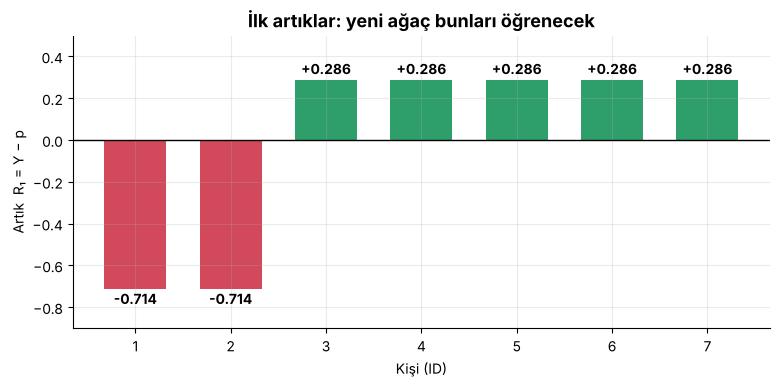

In [5]:
kredi["p (tahmin)"] = p0
kredi["R₁ (artık)"] = kredi["Onay"] - kredi["p (tahmin)"]
display(kredi[["ID", "Maaş (bin)", "Onay", "p (tahmin)", "R₁ (artık)"]].round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
renkler = [RENK["pembe"] if r < 0 else RENK["yesil"] for r in kredi["R₁ (artık)"]]
ax.bar(kredi["ID"], kredi["R₁ (artık)"], color=renkler, width=0.65)
ax.axhline(0, color="black", lw=1)
for i, r in zip(kredi["ID"], kredi["R₁ (artık)"]):
    ax.text(i, r + (0.03 if r > 0 else -0.07), f"{r:+.3f}", ha="center", fontweight="bold")
ax.set(title="İlk artıklar: yeni ağaç bunları öğrenecek", xlabel="Kişi (ID)", ylabel="Artık  R₁ = Y − p", ylim=(-0.9, 0.5))
ax.set_xticks(kredi["ID"])
kaydet(fig, "kavram_03_ilk_artiklar")
plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Bu andan itibaren yeni ağacın **etiketi** artık "onay / ret" değildir; **artıklardır** (−0,714 ve +0,286). Ağaç, "kimin tahmini fazla, kimin eksik kaldı?" sorusunu öğrenir. Bu yüzden boosting'e **"hatadan öğrenen"** denir.

</td></tr></table>

<a id="p6"></a>

<p align="center">
  <img src="assets/kavram_06.svg" width="100%" alt="Bölüm 6">
</p>

Yeni ağacın ilk sorusu hangisi olsun? "Maaş ≤ 50K mı?" "Maaş ≤ 40K mı?" "Kredi skoru düşük mü?" … XGBoost **tüm adayları dener** ve hangisinin artıkları en iyi **gruplara ayırdığını** sayıyla ölçer.

### 🧮 6.1 · İki Formül

$$\text{Benzerlik } S = \frac{\left(\sum R_i\right)^2}{\sum p_i(1-p_i) + \lambda} \qquad\qquad \text{Gain} = S_{sol} + S_{sağ} - S_{kök}$$

- **Benzerlik:** Bir gruptaki artıklar **aynı yöne** bakıyorsa (hepsi + ya da hepsi −) toplamları büyür; grup **"saf"** demektir ve skor yüksek çıkar.
- **Gain:** Bölmenin **kazancı**. Büyük gain = daha iyi soru.
- $\lambda$ (varsayılan 1) düzenleme katsayısıdır (bölüm 9).

<p align="center">
  <img src="assets/diyagram_agac_hesabi.svg" width="100%" alt="Ders notundaki örnek ağaç">
</p>

In [6]:
LAM = 1.0                                           # λ: düzenleme katsayısı

p = np.full(7, p0)                                  # güncel olasılıklar
R = y_kredi - p                                     # artıklar
H = p * (1 - p)                                     # p(1-p): "Hessian" (bölüm 8)


def benzerlik(R_grup, H_grup, lam=LAM):
    """S = (ΣR)² / (Σp(1-p) + λ)"""
    return R_grup.sum() ** 2 / (H_grup.sum() + lam)


def bolunme_kazanci(sol, lam=LAM):
    """Boolean 'sol' maskesine göre gain = S_sol + S_sağ − S_kök"""
    sag = ~sol
    return benzerlik(R[sol], H[sol], lam) + benzerlik(R[sag], H[sag], lam) - benzerlik(R, H, lam)


# ── Ders notundaki bölünme: Maaş ≤ 50K ──
sol = X_kredi[:, 0] <= 50
S_sol, S_sag, S_kok = benzerlik(R[sol], H[sol]), benzerlik(R[~sol], H[~sol]), benzerlik(R, H)
print(f"Sol  (ID 1,2,3)   ΣR = {R[sol].sum():+.3f} · Σp(1-p) = {H[sol].sum():.3f} · S = {S_sol:.3f}   (ders notu: 0.809)")
print(f"Sağ  (ID 4,5,6,7) ΣR = {R[~sol].sum():+.3f} · Σp(1-p) = {H[~sol].sum():.3f} · S = {S_sag:.3f}   (ders notu: 0.702)")
print(f"Kök               ΣR = {R.sum():+.3f}                           S = {S_kok:.3f}")
print(f"Gain = {S_sol:.3f} + {S_sag:.3f} − {S_kok:.3f} = {bolunme_kazanci(sol):.3f}   (ders notu: 1.511)")

Sol  (ID 1,2,3)   ΣR = -1.143 · Σp(1-p) = 0.612 · S = 0.810   (ders notu: 0.809)
Sağ  (ID 4,5,6,7) ΣR = +1.143 · Σp(1-p) = 0.816 · S = 0.719   (ders notu: 0.702)
Kök               ΣR = +0.000                           S = 0.000
Gain = 0.810 + 0.719 − 0.000 = 1.529   (ders notu: 1.511)


<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

**Küçük bir not:** Ders notunda sağ yaprağın benzerliği 0,702 ve gain 1,511 yazılmış. Tam hassasiyetle hesaplayınca sağ yaprak **≈ 0,719** ve gain **≈ 1,529** çıkıyor; fark, ara adımlardaki yuvarlamadan geliyor ve **hiçbir sonucu değiştirmiyor**. Önemli olan hesabın mantığıdır. Buradaki sayıları kütüphaneyle de doğrulayacağız.

</td></tr></table>

### 🔎 6.2 · Notta "Örnek" Denen Bölünme En İyisi mi?

Ders notu bunu açıkça belirtir: *"Bu sadece bir öneri; normalde tüm bölünmeler denenir ve en yüksek gain seçilir."* Şimdi **tüm adayları** deneyelim:

,bölünme,sol ID'ler,gain
0,Maaş ≤ 40K,"[1, 2]",2.459
1,Kredi skoru ≤ 1 (Düşük),"[1, 2]",2.459
2,Maaş ≤ 50K,"[1, 2, 3]",1.529
3,Maaş ≤ 60K,"[1, 2, 3, 4]",0.860
4,Kredi skoru ≤ 2 (Orta),"[1, 2, 3, 5]",0.860
5,Maaş ≤ 30K,[1],0.653
6,Maaş ≤ 70K,"[1, 2, 3, 4, 5]",0.394
7,Maaş ≤ 80K,"[1, 2, 3, 4, 5, 6]",0.104


💾 Kaydedildi → outputs/figures/kavram_04_aday_bolunmeler.png


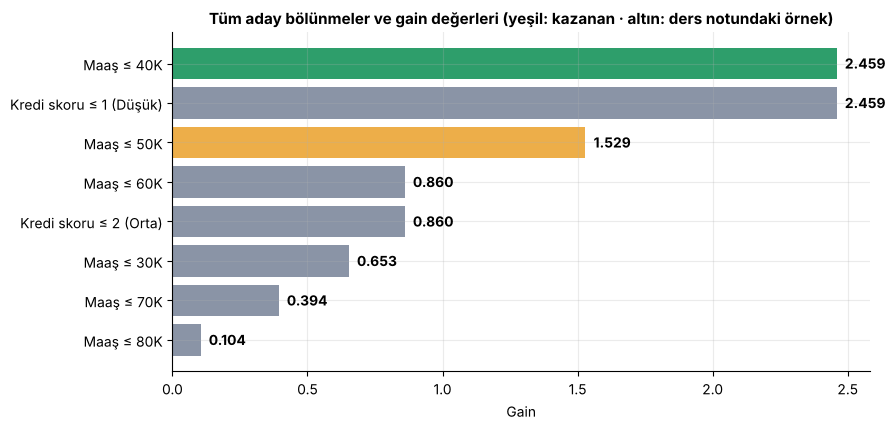

In [7]:
adaylar = []
for f_ad, f_idx in [("Maaş", 0), ("Kredi skoru", 1)]:
    benzersiz = np.sort(np.unique(X_kredi[:, f_idx]))
    for esik in benzersiz[:-1]:                               # en büyük değer eşik olamaz (sağ taraf boş kalır)
        maske = X_kredi[:, f_idx] <= esik
        etiket = f"{f_ad} ≤ {int(esik)}" + ("K" if f_idx == 0 else {1: " (Düşük)", 2: " (Orta)"}[int(esik)])
        adaylar.append({"bölünme": etiket, "sol ID'ler": list(kredi["ID"][maske]), "gain": bolunme_kazanci(maske)})
adaylar = pd.DataFrame(adaylar).sort_values("gain", ascending=False).reset_index(drop=True)
display(adaylar.round(3))

fig, ax = plt.subplots(figsize=(9, 4.4))
renk_bar = [RENK["yesil"] if i == 0 else (RENK["altin"] if "50K" in b else RENK["gri"]) for i, b in enumerate(adaylar["bölünme"])]
ax.barh(adaylar["bölünme"][::-1], adaylar["gain"][::-1], color=renk_bar[::-1])
for i, g in enumerate(adaylar["gain"][::-1]):
    ax.text(g + 0.03, i, f"{g:.3f}", va="center", fontweight="bold")
ax.set(title="Tüm aday bölünmeler ve gain değerleri (yeşil: kazanan · altın: ders notundaki örnek)", xlabel="Gain")
ax.title.set_fontsize(11)
kaydet(fig, "kavram_04_aday_bolunmeler")
plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**Kazanan "Maaş ≤ 40K"** (gain ≈ 2,459): sol grupta yalnızca iki **reddedilen** kişi (ID 1-2) kalır; artıkların ikisi de **negatif** olduğu için grup çok **saf**. Ders notunun örneği olan "Maaş ≤ 50K" (gain ≈ 1,529) iyi ama en iyi değildir. "Kredi skoru ≤ Düşük" da aynı kişileri ayırdığı için **aynı gain**'i verir (eşitlikte kütüphane ilk özelliği seçer).

</td></tr></table>

### 🎞️ 6.3 · Bölünme Tarayıcısı (Animasyon)

Aşağıdaki animasyonda **eşik çizgisi** maaş ekseninde kayıyor; solda artıklar, sağda her eşik için **gain** birikiyor.

💾 Animasyon → outputs/figures/kavram_05_bolunme_tarayici.gif (64 KB)


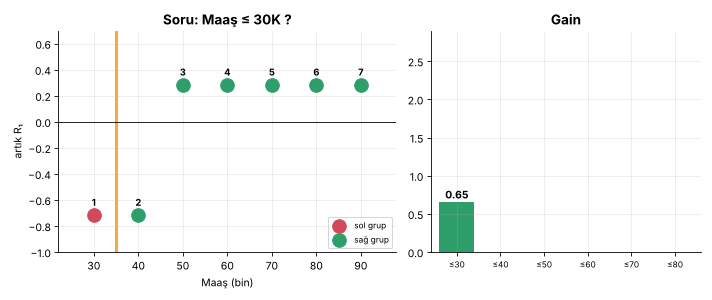

In [8]:
esikler = [30, 40, 50, 60, 70, 80]
kazanc = {e: bolunme_kazanci(X_kredi[:, 0] <= e) for e in esikler}
en_iyi_esik = max(kazanc, key=kazanc.get)


def kare_bolunme(fig, i):
    fig.clf()
    k = min(i // 2, len(esikler) - 1)                           # her eşikte 2 kare bekle
    esik = esikler[k]
    ax1, ax2 = fig.subplots(1, 2, gridspec_kw={"width_ratios": [1.25, 1]})
    sol = X_kredi[:, 0] <= esik
    ax1.scatter(X_kredi[sol, 0], R[sol], s=170, color=RENK["pembe"], zorder=3, label="sol grup")
    ax1.scatter(X_kredi[~sol, 0], R[~sol], s=170, color=RENK["yesil"], zorder=3, label="sağ grup")
    ax1.axvline(esik + 5, color=RENK["altin"], lw=3)
    ax1.axhline(0, color="black", lw=0.8)
    for xx, rr, idd in zip(X_kredi[:, 0], R, kredi["ID"]):
        ax1.text(xx, rr + 0.07, str(idd), ha="center", fontsize=9, fontweight="bold")
    ax1.set(title=f"Soru: Maaş ≤ {esik}K ?", xlabel="Maaş (bin)", ylabel="artık R₁", ylim=(-1, 0.7), xlim=(22, 98))
    ax1.legend(loc="lower right", fontsize=8)
    gorulen = esikler[: k + 1]
    ax2.bar([f"≤{e}" for e in gorulen], [kazanc[e] for e in gorulen],
            color=[RENK["yesil"] if kazanc[e] == max(kazanc[x] for x in gorulen) else RENK["gri"] for e in gorulen])
    for j, e in enumerate(gorulen):
        ax2.text(j, kazanc[e] + 0.05, f"{kazanc[e]:.2f}", ha="center", fontweight="bold")
    ax2.set(title="Gain", ylim=(0, 2.9), xlim=(-0.6, len(esikler) - 0.4))
    ax2.set_xticks(range(len(esikler)))
    ax2.set_xticklabels([f"≤{e}" for e in esikler], fontsize=8)
    fig.tight_layout()


gif_kaydet(kare_bolunme, len(esikler) * 2 + 3, FIG_DIR / "kavram_05_bolunme_tarayici.gif", figsize=(9.5, 4), fps=2)
display(Image(filename=FIG_DIR / "kavram_05_bolunme_tarayici.gif"))

<a id="p7"></a>

<p align="center">
  <img src="assets/kavram_07.svg" width="100%" alt="Bölüm 7">
</p>

Bölünme belli olunca her **yapraktaki** (alt gruptaki) kişiler için tek bir **düzeltme değeri** hesaplanır:

$$V = \frac{\sum R_i}{\sum p_i(1-p_i) + \lambda}$$

Sonra her kişinin log-odds tahmini, **kendi yaprağının değeri × öğrenme hızı (η)** kadar güncellenir:

$$F_1 = F_0 + \eta \cdot V \qquad\Rightarrow\qquad p_{yeni} = \frac{1}{1 + e^{-F_1}}$$

Ders notundaki gibi **η = 0,1** ve bölünme **Maaş ≤ 50K** alalım:

In [9]:
ETA = 0.1                                                   # öğrenme hızı η

V_sol = R[sol].sum() / (H[sol].sum() + LAM)
V_sag = R[~sol].sum() / (H[~sol].sum() + LAM)
print(f"Sol yaprak değeri : {V_sol:+.3f}   (ders notu: −0.709)")
print(f"Sağ yaprak değeri : {V_sag:+.3f}   (ders notu: +0.631)")

yaprak = np.where(sol, V_sol, V_sag)
F0_vec = np.full(7, F0)
F1 = F0_vec + ETA * yaprak
p1 = sigmoid(F1)
R2 = y_kredi - p1

tablo = pd.DataFrame({"ID": kredi["ID"], "F₀": F0_vec, "Yaprak": yaprak, "F₁ = F₀ + η·yaprak": F1, "Yeni p": p1, "Gerçek Y": y_kredi, "R₂ = Y − p": R2})
display(tablo.round(3))
print("\nDers notu (Tablo 3 ve 4): ID1 → F1 = 0.845, p = 0.699, R2 = −0.699 · ID4 → F1 = 0.979, p = 0.727, R2 = +0.273")

Sol yaprak değeri : -0.709   (ders notu: −0.709)
Sağ yaprak değeri : +0.629   (ders notu: +0.631)


,ID,F₀,Yaprak,F₁ = F₀ + η·yaprak,Yeni p,Gerçek Y,R₂ = Y − p
0,1,0.916,-0.709,0.845,0.700,0.0,-0.700
1,2,0.916,-0.709,0.845,0.700,0.0,-0.700
2,3,0.916,-0.709,0.845,0.700,1.0,0.300
3,4,0.916,0.629,0.979,0.727,1.0,0.273
4,5,0.916,0.629,0.979,0.727,1.0,0.273
5,6,0.916,0.629,0.979,0.727,1.0,0.273
6,7,0.916,0.629,0.979,0.727,1.0,0.273



Ders notu (Tablo 3 ve 4): ID1 → F1 = 0.845, p = 0.699, R2 = −0.699 · ID4 → F1 = 0.979, p = 0.727, R2 = +0.273


<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

Sayılar, ders notundaki küçük yuvarlama farkları (ör. sağ yaprak 0,629 ↔ 0,631) dışında **örtüşüyor**. Küçük ama önemli bir ayrıntı: **η = 0,1** olduğu için ID 1'in tahmini 0,916'dan yalnızca 0,845'e indi. XGBoost **büyük adımlar atmak yerine küçük adımlarla** ilerler; böylece tek bir ağaç yanılsa bile model bozulmaz.

</td></tr></table>

### ✅ 7.1 · Gerçek Kütüphane Aynı Şeyi Yapıyor mu?

Elle hesapladığımız şeyi `XGBClassifier` ile **aynı ayarlarla** yaptıralım. Küçük veri için iki ayarı gevşetiyoruz (`min_child_weight=0`, `base_score=5/7`), çünkü varsayılan değerler bu kadar küçük bir örnekte bölünmeye izin vermez.

In [10]:
model_1 = XGBClassifier(n_estimators=1, max_depth=1, learning_rate=ETA, reg_lambda=LAM, gamma=0, min_child_weight=0,
                        base_score=p_onay, tree_method="exact", n_jobs=1, random_state=RANDOM_STATE).fit(X_kredi, y_kredi)
agac = model_1.get_booster().trees_to_dataframe()[["Feature", "Split", "Gain", "Cover", "Node"]]
display(agac)

# Kütüphanenin seçtiği bölünmeyi elle (gain = 2.459) yeniden kuralım ve olasılıkları karşılaştıralım
sol_40 = X_kredi[:, 0] <= 40
V40_sol = R[sol_40].sum() / (H[sol_40].sum() + LAM)
V40_sag = R[~sol_40].sum() / (H[~sol_40].sum() + LAM)
p_elle = sigmoid(F0 + ETA * np.where(sol_40, V40_sol, V40_sag))
p_lib = model_1.predict_proba(X_kredi)[:, 1]
print(f"Kütüphane bölünmesi: Maaş ≤ {agac.loc[0, 'Split'] - 5:.0f}K  (eşik iki komşu değerin ortası: {agac.loc[0, 'Split']:.0f})")
print(f"Kütüphanenin gain'i : {agac.loc[0, 'Gain']:.3f}   ·  bizim hesabımız: {bolunme_kazanci(sol_40):.3f}")
print("Elle olasılıklar    :", p_elle.round(4))
print("Kütüphane           :", p_lib.round(4))
print("En büyük fark       :", f"{np.abs(p_elle - p_lib).max():.2e}")

,Feature,Split,Gain,Cover,Node
0,f0,45.0,2.459376,1.428571,0
1,Leaf,<NA>,-0.101449,0.408163,1
2,Leaf,<NA>,0.070707,1.020408,2


Kütüphane bölünmesi: Maaş ≤ 40K  (eşik iki komşu değerin ortası: 45)
Kütüphanenin gain'i : 2.459   ·  bizim hesabımız: 2.459
Elle olasılıklar    : [0.6931 0.6931 0.7285 0.7285 0.7285 0.7285 0.7285]
Kütüphane           : [0.6931 0.6931 0.7285 0.7285 0.7285 0.7285 0.7285]
En büyük fark       : 3.97e-08


<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

Elle yaptığımız hesap ile `xgboost` **aynı bölünmeyi, aynı gain'i ve aynı olasılıkları** verdi (fark ≈ 10⁻⁸). Yani artık XGBoost bizim için **kara kutu değil**.

</td></tr></table>

### 🎞️ 7.2 · Tur Tur Öğrenen Model (Animasyon)

Bu kez daha iyi izlemek için η = 0,3 ve derinlik 2 kullanıyoruz. Her çubuk, bir kişinin **onay olasılığı**; yıldızlar gerçek etiketler (0 ya da 1). Her turda çubukların yıldızlara yaklaştığına dikkat edin.

💾 Animasyon → outputs/figures/kavram_06_tur_tur_olasilik.gif (84 KB)


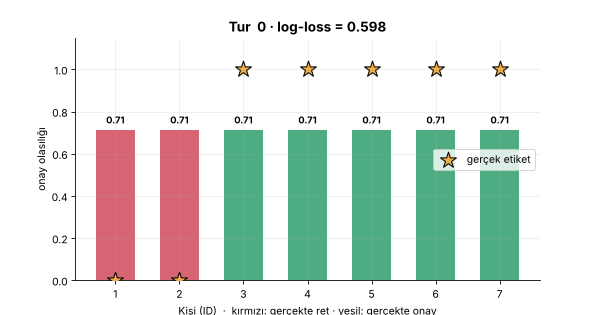

In [11]:
model_anim = XGBClassifier(n_estimators=40, max_depth=2, learning_rate=0.3, reg_lambda=1, min_child_weight=0, gamma=0,
                           base_score=p_onay, tree_method="exact", n_jobs=1, random_state=RANDOM_STATE).fit(X_kredi, y_kredi)
turlar = [0, 1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 40]


def olasilik_k(k):
    """İlk k ağaçla olasılık (k=0 → yalnızca başlangıç)."""
    if k == 0:
        return np.full(7, p_onay)
    return model_anim.predict_proba(X_kredi, iteration_range=(0, k))[:, 1]


def kare_olasilik(fig, i):
    fig.clf()
    ax = fig.add_subplot(111)
    k = turlar[min(i, len(turlar) - 1)]
    pk = olasilik_k(k)
    ax.bar(kredi["ID"], pk, color=[RENK["pembe"] if y == 0 else RENK["yesil"] for y in y_kredi], width=0.6, alpha=0.85)
    ax.scatter(kredi["ID"], y_kredi, marker="*", s=260, color=RENK["altin"], edgecolor="black", zorder=5, label="gerçek etiket")
    for idd, v in zip(kredi["ID"], pk):
        ax.text(idd, v + 0.03, f"{v:.2f}", ha="center", fontsize=9, fontweight="bold")
    kayip = -np.mean(y_kredi * np.log(pk) + (1 - y_kredi) * np.log(1 - pk))
    ax.set(title=f"Tur {k:>2} · log-loss = {kayip:.3f}", xlabel="Kişi (ID)  ·  kırmızı: gerçekte ret · yeşil: gerçekte onay", ylabel="onay olasılığı", ylim=(0, 1.15))
    ax.legend(loc="center right")


gif_kaydet(kare_olasilik, len(turlar) + 3, FIG_DIR / "kavram_06_tur_tur_olasilik.gif", figsize=(8, 4.2), fps=2)
display(Image(filename=FIG_DIR / "kavram_06_tur_tur_olasilik.gif"))

<a id="p8"></a>

<p align="center">
  <img src="assets/kavram_08.svg" width="100%" alt="Bölüm 8">
</p>

Şimdiye kadar "hata" dedik. Aslında XGBoost her örnek için **iki sayı** tutar:

| Sayı | Adı | Anlamı | Log-loss için formül |
|:--|:--|:--|:--|
| **g** | **Gradyan** (1. türev) | Hatanın **ne kadar büyük** olduğu (yönüyle) | $g = p - Y$ |
| **h** | **Hessian** (2. türev) | Bu hatanın **ne kadar hızlı değiştiği** (eğrilik) | $h = p(1-p)$ |

Yaprak değeri tam olarak bu ikisinin oranıdır (artık $R = -g$ olduğuna dikkat edin):

$$\text{güncelleme} = -\frac{\sum g}{\sum h + \lambda}$$

**Sezgi:** Tahmin çok yanlışsa (**büyük g**) büyük bir düzeltme yapılır; zaten iyiyse (**küçük g**) düzeltme küçüktür. **h**, kararsız bölgelerde (p ≈ 0,5) adımı **frenleyerek** modeli daha dengeli kılar.

Ders notundaki örnek: gerçek $Y = 1$, model $p = 0{,}9$ ise $g = 0{,}9 - 1 = -0{,}1$ ve $h = 0{,}9 \cdot 0{,}1 = 0{,}09$ → hata küçük, düzeltme de küçük.

Y=1, p=0.9 → g (formül) = -0.1000 · g (sayısal) = -0.1000
             h (formül) = 0.0900  · h (sayısal) = 0.0900


💾 Kaydedildi → outputs/figures/kavram_07_gradyan_hessian.png


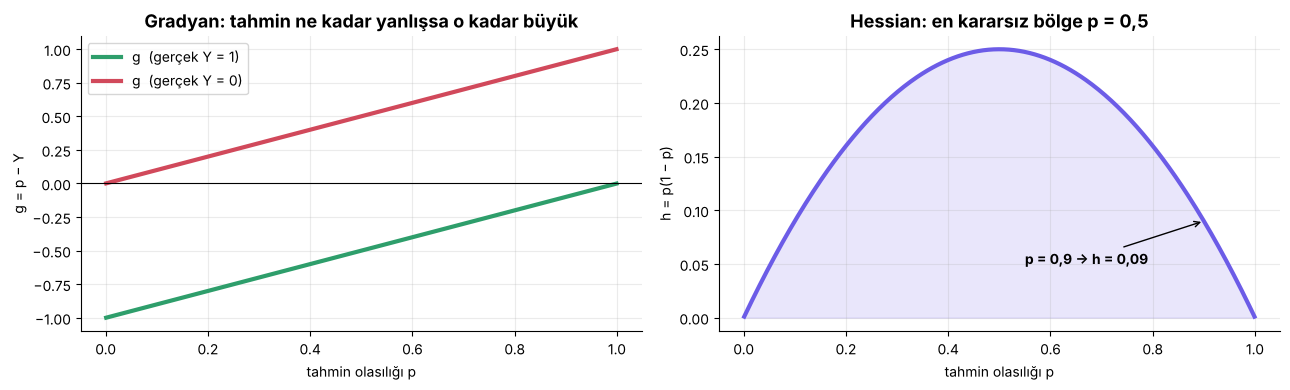

In [12]:
# Sayısal doğrulama: g ve h gerçekten log-loss'un 1. ve 2. türevi mi? (sonlu farklar)
def logloss_F(F, y):
    return -(y * np.log(sigmoid(F)) + (1 - y) * np.log(1 - sigmoid(F)))

y_t, p_t = 1.0, 0.9
F_t = logit(p_t)
d = 1e-4
g_sayisal = (logloss_F(F_t + d, y_t) - logloss_F(F_t - d, y_t)) / (2 * d)
h_sayisal = (logloss_F(F_t + d, y_t) - 2 * logloss_F(F_t, y_t) + logloss_F(F_t - d, y_t)) / d ** 2
print(f"Y=1, p=0.9 → g (formül) = {p_t - y_t:+.4f} · g (sayısal) = {g_sayisal:+.4f}")
print(f"             h (formül) = {p_t * (1 - p_t):.4f}  · h (sayısal) = {h_sayisal:.4f}")

# Görsel: p'ye göre g ve h
pp = np.linspace(0.001, 0.999, 400)
fig, eksen = plt.subplots(1, 2, figsize=(13, 4))
eksen[0].plot(pp, pp - 1, color=RENK["yesil"], lw=3, label="g  (gerçek Y = 1)")
eksen[0].plot(pp, pp - 0, color=RENK["pembe"], lw=3, label="g  (gerçek Y = 0)")
eksen[0].axhline(0, color="black", lw=0.8)
eksen[0].set(title="Gradyan: tahmin ne kadar yanlışsa o kadar büyük", xlabel="tahmin olasılığı p", ylabel="g = p − Y")
eksen[0].legend()
eksen[1].plot(pp, pp * (1 - pp), color=RENK["mor"], lw=3)
eksen[1].fill_between(pp, pp * (1 - pp), color=RENK["mor"], alpha=0.15)
eksen[1].set(title="Hessian: en kararsız bölge p = 0,5", xlabel="tahmin olasılığı p", ylabel="h = p(1 − p)")
eksen[1].annotate("p = 0,9 → h = 0,09", (0.9, 0.09), xytext=(0.55, 0.05), arrowprops=dict(arrowstyle="->"), fontweight="bold")
fig.tight_layout()
kaydet(fig, "kavram_07_gradyan_hessian")
plt.show()

<table><tr><td>

<img src="assets/etiket_kavram.svg" height="34" alt="Kavram">

**Cover** = $\sum h$. Bir düğümdeki örneklerin tahminleri 0'a ya da 1'e çok yakınsa $h$ küçüktür; yani düğüm **fazla bilgi taşımaz** (zaten "çözülmüş"). XGBoost böyle düğümlerde bölünme yapmaz: bu, **otomatik budamanın** temelidir (bölüm 9).

</td></tr></table>

<a id="p9"></a>

<p align="center">
  <img src="assets/kavram_09.svg" width="100%" alt="Bölüm 9">
</p>

XGBoost'u klasik Gradient Boosting'den ayıran en önemli güçlerden biri **düzenlemedir**: model yalnızca hatayı değil, **karmaşıklığını** da küçültmeye çalışır.

<p align="center">
  <img src="assets/diyagram_duzenleme.svg" width="100%" alt="λ, γ ve cover">
</p>

### 🎚️ 9.1 · λ (lambda): Yaprak Değerini Küçültmek

Ders notundaki örnek: bir yaprakta $\sum R = 2$ ve $\sum p(1-p) = 1$ olsun. $\lambda = 1$ iken değer $2/(1+1) = 1$; $\lambda = 10$ iken $2/(1+10) \approx 0{,}18$. λ büyüdükçe **yaprak değeri küçülür**, model daha temkinli olur.

λ → yaprak değeri: {0: 2.0, 1: 1.0, 2: 0.667, 5: 0.333, 10: 0.182, 20: 0.095}


💾 Kaydedildi → outputs/figures/kavram_08_lambda_yaprak.png


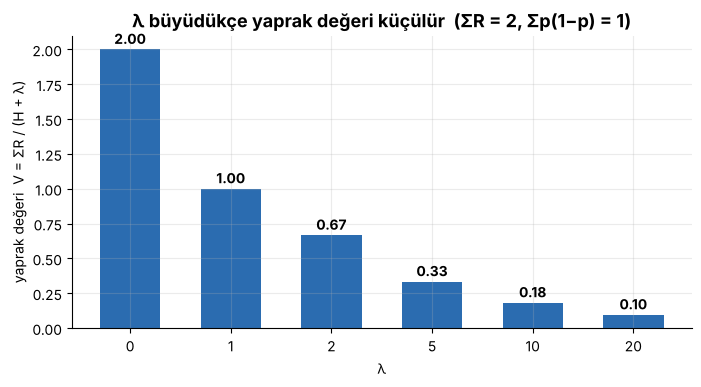

In [13]:
toplam_R, toplam_H = 2.0, 1.0
lambdalar = [0, 1, 2, 5, 10, 20]
degerler = [toplam_R / (toplam_H + l) for l in lambdalar]
print("λ → yaprak değeri:", {l: round(v, 3) for l, v in zip(lambdalar, degerler)})

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar([str(l) for l in lambdalar], degerler, color=RENK["mavi"], width=0.6)
for i, v in enumerate(degerler):
    ax.text(i, v + 0.04, f"{v:.2f}", ha="center", fontweight="bold")
ax.set(title="λ büyüdükçe yaprak değeri küçülür  (ΣR = 2, Σp(1−p) = 1)", xlabel="λ", ylabel="yaprak değeri  V = ΣR / (H + λ)")
kaydet(fig, "kavram_08_lambda_yaprak")
plt.show()

### ✂️ 9.2 · γ (gamma): Zayıf Bölünmeyi Reddetmek

Bölünmeden önce bir **asgari gain** şartı koyarız: gain, γ'dan küçükse XGBoost o bölünmeyi **reddeder** (ağaç **budanır**). Bunu kendi örneğimizde deneyelim: kazanan bölünmenin gain'i **2,459** idi.

In [14]:
satirlar = []
for g in [0, 1.0, 2.4, 2.5, 5.0]:
    m = XGBClassifier(n_estimators=1, max_depth=2, learning_rate=ETA, gamma=g, min_child_weight=0, base_score=p_onay,
                      tree_method="exact", n_jobs=1, random_state=RANDOM_STATE).fit(X_kredi, y_kredi)
    d_ = m.get_booster().trees_to_dataframe()
    satirlar.append({"γ": g, "düğüm sayısı": len(d_), "yaprak sayısı": int((d_["Feature"] == "Leaf").sum()),
                     "kök gain": round(float(d_.loc[0, "Gain"]), 3) if d_.loc[0, "Feature"] != "Leaf" else "— (bölünme yok)"})
display(pd.DataFrame(satirlar))

,γ,düğüm sayısı,yaprak sayısı,kök gain
0,0.0,3,2,2.459
1,1.0,3,2,2.459
2,2.4,3,2,2.459
3,2.5,1,1,— (bölünme yok)
4,5.0,1,1,— (bölünme yok)


<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

γ = 2,4 iken kök bölünme (gain 2,459) **geçer**; γ = 2,5 olduğunda **reddedilir** ve ağaç tek yaprağa iner. Yani γ, "bu bölünme en az şu kadar kazandırmıyorsa yapma" kuralıdır.

</td></tr></table>

### 🧺 9.3 · Gerçek Veride Düzenleme Deneyi

Gürültülü bir "iki ay" verisinde iki XGBoost kuruyoruz:

- **Düzensiz:** derin ağaçlar, λ = 0, γ = 0, `min_child_weight` = 0 → ezberlemeye meyilli
- **Düzenli:** λ = 5, γ = 1, `min_child_weight` = 3 → temkinli

Eğitim ve doğrulama **log-loss** eğrilerini karşılaştırıyoruz.

💾 Kaydedildi → outputs/figures/kavram_09_duzenleme_deneyi.png


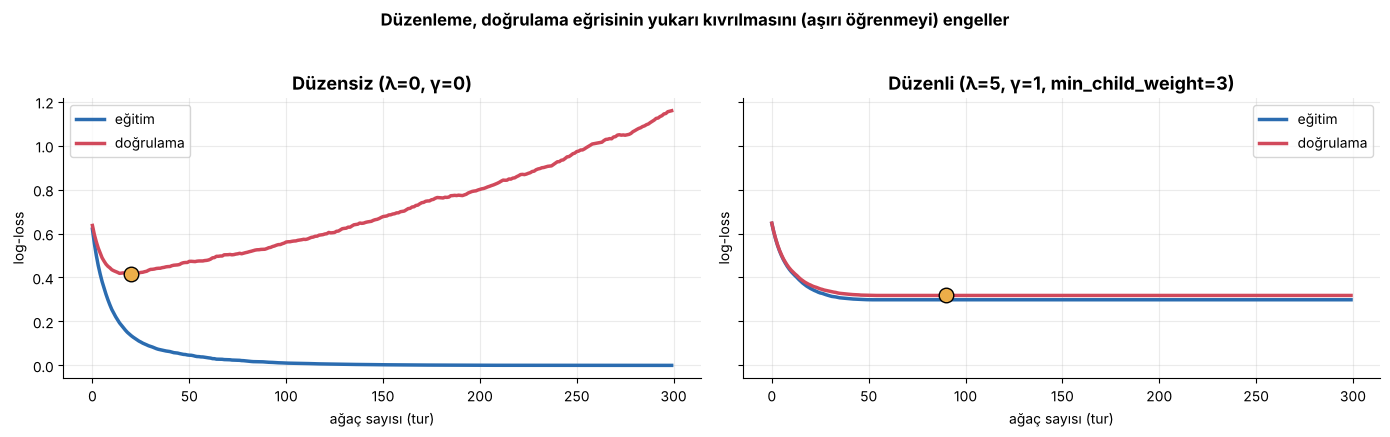

,model,son eğitim kaybı,son doğrulama kaybı,en iyi doğrulama kaybı,en iyi tur,doğrulama doğruluğu
0,"Düzensiz (λ=0, γ=0)",0.000,1.159,0.415,21,0.829
1,"Düzenli (λ=5, γ=1, min_child_weight=3)",0.299,0.318,0.318,91,0.850


In [15]:
Xa, ya = make_moons(n_samples=700, noise=0.35, random_state=RANDOM_STATE)
Xa_egitim, Xa_dogrulama, ya_egitim, ya_dogrulama = train_test_split(Xa, ya, test_size=0.4, random_state=RANDOM_STATE, stratify=ya)

ortak = dict(n_estimators=300, learning_rate=0.1, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1)
duzensiz = XGBClassifier(max_depth=8, reg_lambda=0, gamma=0, min_child_weight=0, **ortak)
duzenli = XGBClassifier(max_depth=8, reg_lambda=5, gamma=1, min_child_weight=3, **ortak)

fig, eksen = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
sonuc_duzen = []
for ax, model, ad in zip(eksen, [duzensiz, duzenli], ["Düzensiz (λ=0, γ=0)", "Düzenli (λ=5, γ=1, min_child_weight=3)"]):
    model.fit(Xa_egitim, ya_egitim, eval_set=[(Xa_egitim, ya_egitim), (Xa_dogrulama, ya_dogrulama)], verbose=False)
    gecmis = model.evals_result()
    egitim_kayip, dogrulama_kayip = gecmis["validation_0"]["logloss"], gecmis["validation_1"]["logloss"]
    ax.plot(egitim_kayip, color=RENK["mavi"], lw=2.5, label="eğitim")
    ax.plot(dogrulama_kayip, color=RENK["pembe"], lw=2.5, label="doğrulama")
    en_iyi = int(np.argmin(dogrulama_kayip))
    ax.scatter([en_iyi], [dogrulama_kayip[en_iyi]], s=110, color=RENK["altin"], edgecolor="black", zorder=5)
    ax.set(title=ad, xlabel="ağaç sayısı (tur)", ylabel="log-loss")
    ax.legend()
    sonuc_duzen.append({"model": ad, "son eğitim kaybı": egitim_kayip[-1], "son doğrulama kaybı": dogrulama_kayip[-1],
                        "en iyi doğrulama kaybı": dogrulama_kayip[en_iyi], "en iyi tur": en_iyi + 1,
                        "doğrulama doğruluğu": (model.predict(Xa_dogrulama) == ya_dogrulama).mean()})
fig.suptitle("Düzenleme, doğrulama eğrisinin yukarı kıvrılmasını (aşırı öğrenmeyi) engeller", fontweight="bold", y=1.03)
fig.tight_layout()
kaydet(fig, "kavram_09_duzenleme_deneyi")
plt.show()
display(pd.DataFrame(sonuc_duzen).round(3))

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Düzensiz modelde **eğitim kaybı** sıfıra doğru iner ama **doğrulama kaybı** bir noktadan sonra **yükselir**: model gürültüyü ezberlemeye başlamıştır. Düzenli modelde ise doğrulama eğrisi daha **düz ve düşük** kalır. Pratik kural: önce `max_depth` ve `learning_rate`'i, sonra λ, γ ve `min_child_weight`'i ayarlayın; **erken durdurma** ile de en iyi turu bulun.

</td></tr></table>

<a id="p10"></a>

<p align="center">
  <img src="assets/kavram_10.svg" width="100%" alt="Bölüm 10">
</p>

### 🏎️ 10.1 · Öğrenme Hızı Yarışı (Animasyon)

**Öğrenme hızı (η)**, her ağacın düzeltmesinin ne kadarının uygulanacağıdır. Üç yarışçı aynı veriyle başlıyor:

- 🐢 **η = 0,02** → çok temkinli, çok ağaç ister
- 🚗 **η = 0,1** → dengeli
- 🚀 **η = 0,5** → atak; hızlı ama gürültüyü de kapabilir

Eğri, model ağaç ekledikçe nasıl şekilleniyor, izleyin.

💾 Animasyon → outputs/figures/kavram_10_ogrenme_hizi_yarisi.gif (165 KB)


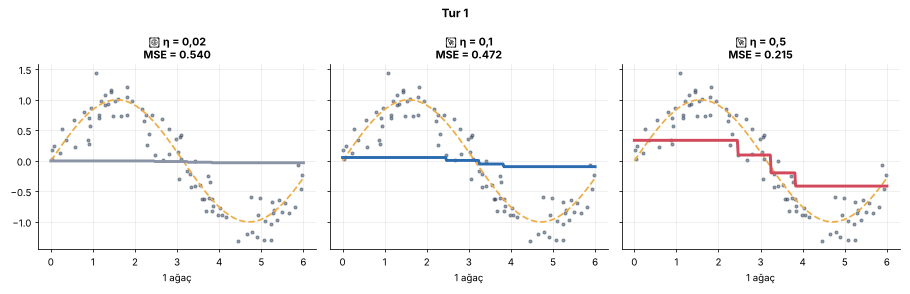

In [16]:
rng = np.random.default_rng(7)
xr = np.sort(rng.uniform(0, 6, 90))
yr = np.sin(xr) + 0.25 * rng.normal(size=xr.size)
Xr = xr.reshape(-1, 1)
izg = np.linspace(0, 6, 300).reshape(-1, 1)
ETALAR = [0.02, 0.1, 0.5]
yarisci = [XGBRegressor(n_estimators=120, max_depth=2, learning_rate=e, reg_lambda=1, random_state=RANDOM_STATE, n_jobs=1).fit(Xr, yr) for e in ETALAR]
turlar_r = [1, 2, 3, 5, 8, 12, 20, 30, 45, 70, 100, 120]
ad_yaris = ["🐢 η = 0,02", "🚗 η = 0,1", "🚀 η = 0,5"]
renk_yaris = [RENK["gri"], RENK["mavi"], RENK["pembe"]]


def kare_yaris(fig, i):
    fig.clf()
    k = turlar_r[min(i, len(turlar_r) - 1)]
    eksen = fig.subplots(1, 3, sharey=True)
    for ax, m, ad, r in zip(eksen, yarisci, ad_yaris, renk_yaris):
        tahmin = m.predict(izg, iteration_range=(0, k))
        hata = np.mean((m.predict(Xr, iteration_range=(0, k)) - yr) ** 2)
        ax.scatter(xr, yr, s=10, color=RENK["koyu"], alpha=0.5)
        ax.plot(izg, np.sin(izg), "--", color=RENK["altin"], lw=1.8)
        ax.plot(izg, tahmin, color=r, lw=3)
        ax.set_title(f"{ad}\nMSE = {hata:.3f}", fontsize=11)
        ax.set_xlabel(f"{k} ağaç")
    fig.suptitle(f"Tur {k}", fontweight="bold")
    fig.tight_layout()


gif_kaydet(kare_yaris, len(turlar_r) + 3, FIG_DIR / "kavram_10_ogrenme_hizi_yarisi.gif", figsize=(13, 4.2), fps=2, dpi=70)
display(Image(filename=FIG_DIR / "kavram_10_ogrenme_hizi_yarisi.gif"))

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**Küçük η** daha yavaş ama daha **sakin** ilerler; **büyük η** hızla yaklaşır ama gürültüyü de yakalayabilir. Tipik reçete: **küçük η + yeterince çok ağaç + erken durdurma**. İkisi birbirini dengeler: η'yı yarıya indirirseniz, aynı kaliteye yaklaşmak için kabaca **iki kat ağaç** gerekir.

</td></tr></table>

### 🔍 10.2 · Hata Avcısı (Animasyon)

Her turda **üst panel** modelin güncel tahminini, **alt panel** ise ağacın o turda **öğrendiği artıkları ve önerdiği basamaklı düzeltmeyi** gösterir.

💾 Animasyon → outputs/figures/kavram_11_hata_avcisi.gif (164 KB)


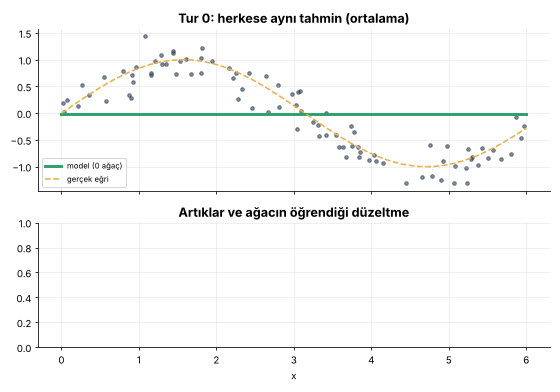

In [17]:
av_model = XGBRegressor(n_estimators=12, max_depth=2, learning_rate=0.5, reg_lambda=1, random_state=RANDOM_STATE, n_jobs=1).fit(Xr, yr)
base = av_model.get_params().get("base_score")
taban = float(np.mean(yr))                                           # regresyonda başlangıç = ortalama


def tahmin_k(k, X):
    return np.full(len(X), taban) if k == 0 else av_model.predict(X, iteration_range=(0, k))


def kare_hata_avcisi(fig, i):
    fig.clf()
    k = min(i, 12)
    ust, alt = fig.subplots(2, 1, sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
    onceki = tahmin_k(k - 1 if k > 0 else 0, Xr)
    ust.scatter(xr, yr, s=14, color=RENK["koyu"], alpha=0.6)
    ust.plot(izg, tahmin_k(k, izg), color=RENK["yesil"], lw=3, label=f"model ({k} ağaç)")
    ust.plot(izg, np.sin(izg), "--", color=RENK["altin"], lw=1.6, label="gerçek eğri")
    ust.legend(loc="lower left", fontsize=8)
    ust.set_title(f"Tur {k}: güncel tahmin" if k else "Tur 0: herkese aynı tahmin (ortalama)")
    if k > 0:
        artik = yr - onceki
        yeni_duzeltme = (tahmin_k(k, izg) - tahmin_k(k - 1, izg)) / 0.5            # η'ya bölerek ağacın ham yaprak değerleri
        alt.scatter(xr, artik, s=14, color=RENK["pembe"], alpha=0.7, label="artık (gerçek − önceki tahmin)")
        alt.step(izg.ravel(), yeni_duzeltme, where="mid", color=RENK["mavi"], lw=3, label="yeni ağacın önerisi")
        alt.axhline(0, color="black", lw=0.7)
        alt.legend(loc="lower left", fontsize=8)
    alt.set(title="Artıklar ve ağacın öğrendiği düzeltme", xlabel="x")
    fig.tight_layout()


gif_kaydet(kare_hata_avcisi, 16, FIG_DIR / "kavram_11_hata_avcisi.gif", figsize=(8, 5.6), fps=2, dpi=70)
display(Image(filename=FIG_DIR / "kavram_11_hata_avcisi.gif"))

### ⚡ 10.3 · Neden "Extreme"? Hız Karşılaştırması

XGBoost'un adındaki *extreme*, yalnızca algoritma değil **mühendislik** için de geçerlidir: paralel bölünme arama, histogram tabanlı yöntem, bellek ve önbellek optimizasyonları (Chen ve Guestrin, 2016). Aynı veride **eğitim sürelerini** ölçelim (her model 100 ağaç, derinlik 4):

,yöntem,eğitim süresi (sn),test doğruluğu
0,XGBoost · hist · 1 çekirdek,0.269,0.947
1,XGBoost · hist · tüm çekirdekler,0.987,0.947
2,XGBoost · exact · 1 çekirdek,2.764,0.944
3,scikit-learn GradientBoosting,13.152,0.925
4,LightGBM,33.069,0.924
5,scikit-learn HistGradientBoosting,48.039,0.922


💾 Kaydedildi → outputs/figures/kavram_12_hiz.png


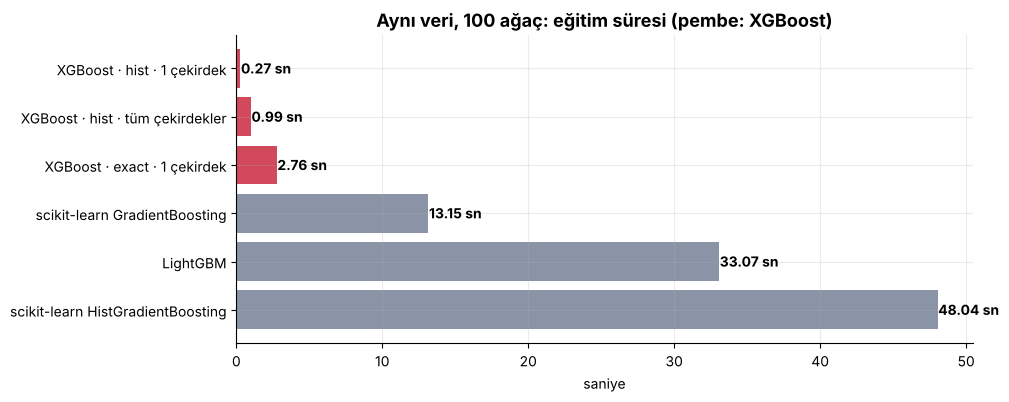

In [18]:
Xh, yh = make_classification(n_samples=25000, n_features=25, n_informative=12, random_state=RANDOM_STATE)
Xh_egitim, Xh_test, yh_egitim, yh_test = train_test_split(Xh, yh, test_size=0.3, random_state=RANDOM_STATE)
from lightgbm import LGBMClassifier

adaylar_hiz = {
    "scikit-learn GradientBoosting": GradientBoostingClassifier(n_estimators=100, max_depth=4, random_state=RANDOM_STATE),
    "XGBoost · exact · 1 çekirdek": XGBClassifier(n_estimators=100, max_depth=4, tree_method="exact", n_jobs=1, random_state=RANDOM_STATE),
    "XGBoost · hist · 1 çekirdek": XGBClassifier(n_estimators=100, max_depth=4, tree_method="hist", n_jobs=1, random_state=RANDOM_STATE),
    "XGBoost · hist · tüm çekirdekler": XGBClassifier(n_estimators=100, max_depth=4, tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE),
    "scikit-learn HistGradientBoosting": HistGradientBoostingClassifier(max_iter=100, max_depth=4, random_state=RANDOM_STATE),
    "LightGBM": LGBMClassifier(n_estimators=100, max_depth=4, verbose=-1, random_state=RANDOM_STATE),
}
satir_hiz = []
for ad, m in adaylar_hiz.items():
    t0 = time.perf_counter()
    m.fit(Xh_egitim, yh_egitim)
    sure = time.perf_counter() - t0
    satir_hiz.append({"yöntem": ad, "eğitim süresi (sn)": sure, "test doğruluğu": (m.predict(Xh_test) == yh_test).mean()})
hiz = pd.DataFrame(satir_hiz).sort_values("eğitim süresi (sn)").reset_index(drop=True)
display(hiz.round(3))

fig, ax = plt.subplots(figsize=(9.5, 4))
ax.barh(hiz["yöntem"][::-1], hiz["eğitim süresi (sn)"][::-1], color=[RENK["pembe"] if "XGBoost" in a else RENK["gri"] for a in hiz["yöntem"][::-1]])
for i, v in enumerate(hiz["eğitim süresi (sn)"][::-1]):
    ax.text(v + 0.05, i, f"{v:.2f} sn", va="center", fontweight="bold")
ax.set(title="Aynı veri, 100 ağaç: eğitim süresi (pembe: XGBoost)", xlabel="saniye")
kaydet(fig, "kavram_12_hiz")
plt.show()

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

Süreler **makineye bağlıdır**; önemli olan oran ve sıralamadır. `tree_method="hist"` (varsayılan) veriyi **kutulara (histogram)** böler ve bölünme adaylarını çok azaltır; bu yüzden büyük veride "exact"ten çok daha hızlıdır. Doğruluklar birbirine yakındır: XGBoost hızı **kaliteden ödün vermeden** artırır.

</td></tr></table>

<a id="p11"></a>

<p align="center">
  <img src="assets/kavram_11.svg" width="100%" alt="Bölüm 11">
</p>

XGBoost yalnızca sınıflandırma için değil **sayı tahmini** için de güçlüdür. Mantık **aynıdır**, formüller **daha basittir**: log-odds ve sigmoid yoktur; başlangıç tahmini **ortalamadır**, artık ise doğrudan **gerçek − tahmin**'dir.

Ders notundaki regresyon örneği: maaş ve kredi skoruna göre **harcama miktarını** tahmin ediyoruz.

In [19]:
harcama = pd.DataFrame({"ID": range(1, 8), "Maaş (bin)": [30, 40, 50, 60, 70, 80, 90],
                        "Kredi skoru": ["Düşük", "Düşük", "Orta", "Yüksek", "Orta", "Yüksek", "Yüksek"],
                        "Harcama": [2000, 3000, 4000, 5000, 6000, 7000, 8000]})
yh_ = harcama["Harcama"].to_numpy(float)
F0_r = yh_.mean()                         # başlangıç: ortalama
R1_r = yh_ - F0_r                         # ilk artıklar
print(f"Başlangıç tahmini F0 = ortalama = {F0_r:.0f}   (ders notu: 5000)")

# Regresyonda (λ=0, kare hata): gain = (ΣR_sol)²/N_sol + (ΣR_sağ)²/N_sağ − (ΣR)²/N
sol_r = X_kredi[:, 0] <= 60
gain_r = R1_r[sol_r].sum() ** 2 / sol_r.sum() + R1_r[~sol_r].sum() ** 2 / (~sol_r).sum() - R1_r.sum() ** 2 / 7
V_sol_r, V_sag_r = R1_r[sol_r].mean(), R1_r[~sol_r].mean()          # yaprak = artıkların ortalaması
print(f"Maaş ≤ 60K  →  gain = {gain_r:,.0f}  (ders notu: 21,000,000)")
print(f"Yaprak değerleri: sol = {V_sol_r:+.0f}, sağ = {V_sag_r:+.0f}   (ders notu: −1500 ve +2000)")

F1_r = F0_r + 0.1 * np.where(sol_r, V_sol_r, V_sag_r)
tablo_r = pd.DataFrame({"ID": harcama["ID"], "Gerçek Y": yh_, "F₀": F0_r, "Yaprak": np.where(sol_r, V_sol_r, V_sag_r), "F₁": F1_r, "R₂ = Y − F₁": yh_ - F1_r})
display(tablo_r.round(0))

# Gerçek kütüphane (λ=0, η=0.1, 1 ağaç): aynı sayılar mı?
m_r = XGBRegressor(n_estimators=1, max_depth=1, learning_rate=0.1, reg_lambda=0, min_child_weight=0, base_score=F0_r,
                   tree_method="exact", n_jobs=1, random_state=RANDOM_STATE).fit(X_kredi, yh_)
print("\nKütüphane tahminleri:", m_r.predict(X_kredi))
print("Elle tahminler      :", F1_r)

Başlangıç tahmini F0 = ortalama = 5000   (ders notu: 5000)
Maaş ≤ 60K  →  gain = 21,000,000  (ders notu: 21,000,000)
Yaprak değerleri: sol = -1500, sağ = +2000   (ders notu: −1500 ve +2000)


,ID,Gerçek Y,F₀,Yaprak,F₁,R₂ = Y − F₁
0,1,2000.0,5000.0,-1500.0,4850.0,-2850.0
1,2,3000.0,5000.0,-1500.0,4850.0,-1850.0
2,3,4000.0,5000.0,-1500.0,4850.0,-850.0
3,4,5000.0,5000.0,-1500.0,4850.0,150.0
4,5,6000.0,5000.0,2000.0,5200.0,800.0
5,6,7000.0,5000.0,2000.0,5200.0,1800.0
6,7,8000.0,5000.0,2000.0,5200.0,2800.0



Kütüphane tahminleri: [4850. 4850. 4850. 4850. 5200. 5200. 5200.]
Elle tahminler      : [4850. 4850. 4850. 4850. 5200. 5200. 5200.]


<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

Elle hesap, ders notu ve kütüphane **aynı sonucu** veriyor (4850 ve 5200). Regresyonda λ, yaprak formülüne şöyle girer: $V = \sum R / (N + \lambda)$.

</td></tr></table>

### 🆚 11.1 · Sınıflandırma ile Regresyon

| | **Sınıflandırma** | **Regresyon** |
|:--|:--|:--|
| Başlangıç | log-odds ($\log(\text{pozitif}/\text{negatif})$) | hedefin ortalaması |
| Artık | $Y - p$ (olasılık farkı) | $Y - F$ (sayı farkı) |
| Hessian | $p(1-p)$ | 1 (her örnek için) |
| Yaprak değeri | $\sum R / (\sum p(1-p) + \lambda)$ | $\sum R / (N + \lambda)$ |
| Son adım | **sigmoid** ile olasılık | doğrudan sayı |
| Güncelleme adımları | aynı | aynı |

<a id="p12"></a>

<p align="center">
  <img src="assets/kavram_12.svg" width="100%" alt="Bölüm 12">
</p>

Şimdi XGBoost'u **gerçek bir probleme** bakarken izleyelim: **Sloan Digital Sky Survey (SDSS)** gökyüzü taramasından 10.000 gök cismi (York vd., 2000). Her cisim **yıldız**, **galaksi** ya da **kuasar** olarak etiketli; biz yalnızca iki "renk" ölçümüne (u−g ve g−r) bakarak sınıfı tahmin etmeye çalışacağız. Projenin ayrıntısı bir sonraki notebook'ta; burada amaç **karar sınırının tur tur büyümesini** görmek.

<p align="center">
  <img src="assets/diyagram_sdss.svg" width="100%" alt="SDSS: ışığı beş renkte ölçmek">
</p>

Sınıflar: {'GALAXY': 0, 'QSO': 1, 'STAR': 2} · Satır: 9843


120 ağaçlı model · test doğruluğu = 0.837


💾 Animasyon → outputs/figures/kavram_13_karar_siniri.gif (271 KB)


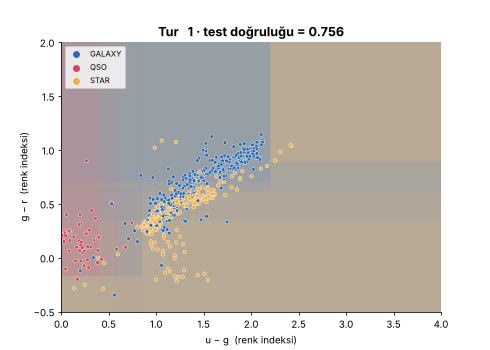

In [20]:
sky = pd.read_csv("20-digitalskysurvey.csv")
sky["u_g"] = sky["u"] - sky["g"]                              # renk indeksi: u − g
sky["g_r"] = sky["g"] - sky["r"]                              # renk indeksi: g − r
sky = sky[(sky["u_g"].between(0, 4)) & (sky["g_r"].between(-0.5, 2))].reset_index(drop=True)   # çizim için uç değerleri kırp
le = LabelEncoder()
sky["y"] = le.fit_transform(sky["class"])                     # GALAXY=0, QSO=1, STAR=2
print("Sınıflar:", dict(zip(le.classes_, range(3))), "· Satır:", len(sky))

X2 = sky[["u_g", "g_r"]].to_numpy()
y2 = sky["y"].to_numpy()
X2_egitim, X2_test, y2_egitim, y2_test = train_test_split(X2, y2, test_size=0.3, random_state=RANDOM_STATE, stratify=y2)

sky_model = XGBClassifier(n_estimators=120, max_depth=3, learning_rate=0.3, objective="multi:softprob", random_state=RANDOM_STATE, n_jobs=1)
sky_model.fit(X2_egitim, y2_egitim)
print(f"120 ağaçlı model · test doğruluğu = {(sky_model.predict(X2_test) == y2_test).mean():.3f}")

SINIF_RENK = ["#2B6CB0", "#D1495B", "#EDAE49"]                # galaksi: mavi · kuasar: pembe · yıldız: altın
gx, gy = np.meshgrid(np.linspace(0, 4, 160), np.linspace(-0.5, 2, 160))
izgara_2d = np.c_[gx.ravel(), gy.ravel()]
tur_sky = [1, 2, 3, 5, 8, 12, 20, 35, 60, 90, 120]
renk_mat = np.array([matplotlib_rgb for matplotlib_rgb in [plt.matplotlib.colors.to_rgb(c) for c in SINIF_RENK]])


def kare_sky(fig, i):
    fig.clf()
    ax = fig.add_subplot(111)
    k = tur_sky[min(i, len(tur_sky) - 1)]
    olas = sky_model.predict_proba(izgara_2d, iteration_range=(0, k))
    gorsel = (olas @ renk_mat).reshape(gx.shape + (3,))                              # sınıf olasılıklarıyla renk karışımı
    ax.imshow(gorsel, extent=(0, 4, -0.5, 2), origin="lower", aspect="auto", alpha=0.75)
    ornek = np.random.default_rng(1).choice(len(X2_test), 600, replace=False)
    ax.scatter(X2_test[ornek, 0], X2_test[ornek, 1], c=[SINIF_RENK[c] for c in y2_test[ornek]], s=14, edgecolor="white", linewidth=0.4)
    dogruluk = (sky_model.predict_proba(X2_test, iteration_range=(0, k)).argmax(1) == y2_test).mean()
    ax.set(title=f"Tur {k:>3} · test doğruluğu = {dogruluk:.3f}", xlabel="u − g  (renk indeksi)", ylabel="g − r  (renk indeksi)", xlim=(0, 4), ylim=(-0.5, 2))
    ax.grid(False)
    for ad, r in zip(le.classes_, SINIF_RENK):
        ax.scatter([], [], color=r, label=ad)
    ax.legend(loc="upper left", fontsize=8)


gif_kaydet(kare_sky, len(tur_sky) + 3, FIG_DIR / "kavram_13_karar_siniri.gif", figsize=(7, 5), fps=2, dpi=70)
display(Image(filename=FIG_DIR / "kavram_13_karar_siniri.gif"))

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

İlk turda model yalnızca **en kalabalık sınıfı** boyar. Her yeni ağaç, öncekilerin **yanlış boyadığı bölgeleri** düzeltir; bölgeler yuvarlak ve dengeli hâle gelir. **Yalnızca iki renk** bile sınıfların çoğunu ayırabiliyor; ama sınıflar iç içe geçtiği yerde (özellikle kuasarlarla yıldızlar) karışıklık sürüyor. Projede **redshift** ve diğer ölçümlerle bu sorunu çözmeyi deneyeceğiz.

</td></tr></table>

<a id="p13"></a>

<p align="center">
  <img src="assets/kavram_13.svg" width="100%" alt="Bölüm 13">
</p>

Öğrendiklerimizi **tek bir sınıfta** toplayalım: yaklaşık 40 satırlık bir **mini XGBoost** (ikili sınıflandırma). İçinde bu derste gördüğümüz her şey var: log-odds başlangıcı, gradyan ve Hessian, benzerlik/gain hesabı, λ ve γ, yaprak değeri, öğrenme hızı.

In [21]:
class MiniXGB:
    """Öğrenmek için yazılmış mini XGBoost (ikili sınıflandırma, kesin/exact bölünme araması)."""

    def __init__(self, n_tur=20, eta=0.3, derinlik=3, lam=1.0, gamma=0.0, min_hess=1.0):
        self.n_tur, self.eta, self.derinlik, self.lam, self.gamma, self.min_hess = n_tur, eta, derinlik, lam, gamma, min_hess

    def _agac(self, X, g, h, idx, d):
        G, H = g[idx].sum(), h[idx].sum()
        yaprak = {"deger": -G / (H + self.lam)}                                    # yaprak değeri  V = −Σg / (Σh + λ)
        if d == self.derinlik or len(idx) < 2:
            return yaprak
        en_iyi = (0.0, None, None)                                                 # (gain, özellik, eşik)
        for f in range(X.shape[1]):
            o = idx[np.argsort(X[idx, f], kind="stable")]
            xs = X[o, f]
            GL, HL = np.cumsum(g[o])[:-1], np.cumsum(h[o])[:-1]                    # her eşik için sol toplamlar
            GR, HR = G - GL, H - HL
            gain = GL ** 2 / (HL + self.lam) + GR ** 2 / (HR + self.lam) - G ** 2 / (H + self.lam)
            gecerli = (xs[1:] > xs[:-1]) & (HL >= self.min_hess) & (HR >= self.min_hess)
            if gecerli.any():
                k = np.where(gecerli, gain, -np.inf)
                j = k.argmax()
                if k[j] > en_iyi[0]:
                    en_iyi = (k[j], f, (xs[j] + xs[j + 1]) / 2)
        if en_iyi[1] is None or en_iyi[0] <= max(self.gamma, 1e-6):                # γ: yeterince kazandırmayan bölünme yok
            return yaprak
        _, f, t = en_iyi
        return {"f": f, "t": t, "sol": self._agac(X, g, h, idx[X[idx, f] < t], d + 1), "sag": self._agac(X, g, h, idx[X[idx, f] >= t], d + 1)}

    def _tek(self, a, x):
        while "f" in a:
            a = a["sol"] if x[a["f"]] < a["t"] else a["sag"]
        return a["deger"]

    def fit(self, X, y):
        self.F0 = logit(y.mean())                                                  # 1) başlangıç: log-odds
        F, self.agaclar = np.full(len(y), self.F0), []
        for _ in range(self.n_tur):
            p = sigmoid(F)
            g, h = p - y, p * (1 - p)                                              # 2) gradyan ve Hessian
            a = self._agac(X, g, h, np.arange(len(y)), 0)                          # 3-4) ağaç + yaprak değerleri
            self.agaclar.append(a)
            F = F + self.eta * np.array([self._tek(a, x) for x in X])              # 5) güncelle
        return self

    def predict_proba(self, X):
        F = np.full(len(X), self.F0)
        for a in self.agaclar:
            F = F + self.eta * np.array([self._tek(a, x) for x in X])
        return sigmoid(F)

### ✅ 13.1 · Doğrulama: Mini XGBoost = Gerçek XGBoost mu?

Kütüphanede bulunan **göğüs kanseri** veri setini (`scikit-learn` ile birlikte gelir, internet gerekmez) kullanıyoruz. İki modele **aynı ayarları** veriyoruz.

En büyük olasılık farkı : 8.22e-08
Aynı sınıf kararı oranı : 1.000
Test doğruluğu · mini = 0.959 · XGBoost = 0.959


💾 Kaydedildi → outputs/figures/kavram_14_mini_xgboost_dogrulama.png


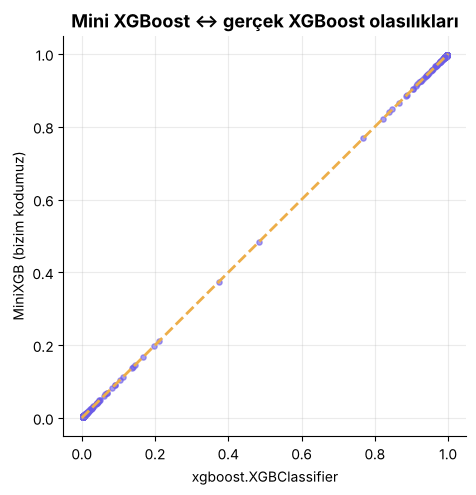

In [22]:
from sklearn.datasets import load_breast_cancer
kanser = load_breast_cancer()
Xk, yk = kanser.data[:400], kanser.target[:400].astype(float)

mini = MiniXGB(n_tur=20, eta=0.3, derinlik=3, lam=1.0, gamma=0.0, min_hess=1.0).fit(Xk, yk)
gercek = XGBClassifier(n_estimators=20, learning_rate=0.3, max_depth=3, reg_lambda=1, gamma=0, min_child_weight=1,
                       base_score=yk.mean(), tree_method="exact", n_jobs=1, random_state=RANDOM_STATE).fit(Xk, yk)

p_mini, p_gercek = mini.predict_proba(Xk), gercek.predict_proba(Xk)[:, 1]
print(f"En büyük olasılık farkı : {np.abs(p_mini - p_gercek).max():.2e}")
print(f"Aynı sınıf kararı oranı : {((p_mini > 0.5) == (p_gercek > 0.5)).mean():.3f}")

# Test: hiç görülmemiş 169 hasta
Xt, yt = kanser.data[400:], kanser.target[400:]
print(f"Test doğruluğu · mini = {((mini.predict_proba(Xt) > 0.5) == yt).mean():.3f} · XGBoost = {(gercek.predict(Xt) == yt).mean():.3f}")

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.scatter(p_gercek, p_mini, s=14, color=RENK["mor"], alpha=0.6)
ax.plot([0, 1], [0, 1], "--", color=RENK["altin"], lw=2)
ax.set(title="Mini XGBoost ↔ gerçek XGBoost olasılıkları", xlabel="xgboost.XGBClassifier", ylabel="MiniXGB (bizim kodumuz)")
kaydet(fig, "kavram_14_mini_xgboost_dogrulama")
plt.show()

<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

Elle yazdığımız mini model, kütüphaneyle **~10⁻⁷ düzeyinde aynı olasılıkları** üretiyor ve aynı kararları veriyor. Gerçek XGBoost'un geri kalanı **mühendislik**: histogram, paralellik, eksik değer yönetimi, çok sınıf, erken durdurma, GPU desteği… Ama **algoritmanın kalbi bu 40 satırdır.**

</td></tr></table>

<a id="p14"></a>

<p align="center">
  <img src="assets/kavram_14.svg" width="100%" alt="Bölüm 14">
</p>

### 🆚 14.1 · Karşılaştırma Tablosu

| | **Random Forest** | **AdaBoost** | **Gradient Boosting** | **XGBoost** |
|:--|:--|:--|:--|:--|
| Ağaçlar nasıl bir araya gelir? | **Paralel**, bağımsız; ortalama/oy | **Sıralı**; yanlış örneklere ağırlık | **Sıralı**; kalan hatayı (artığı) öğrenir | **Sıralı**; artık + **2. türev** |
| Ağaç boyu | Derin | Çok sığ (kütük) | Sığ | Sığ, **budanır** |
| Düzenleme | Rastgelelik | Öğrenme hızı | Öğrenme hızı, alt örnekleme | **λ, α, γ, min_child_weight**, alt örnekleme |
| Hız | Paralel kolay | Orta | Yavaş | **Çok hızlı** (histogram, paralel) |
| Eksik değer | Doldurmak gerekir | Doldurmak gerekir | Doldurmak gerekir | **Kendi yönetir** |
| Güçlü yanı | Basit, sağlam | Sezgisel | Esnek kayıp işlevi | Tablo verisinde **sıklıkla en iyiler arasında** |

Derin öğrenme yöntemlerinin güncel kıyaslamalarında bile **ağaç tabanlı modeller**, orta büyüklükteki tablo verilerinde hâlâ çok rekabetçidir (Grinsztajn vd., 2022); bu yüzden XGBoost iş dünyasında ve yarışmalarda sık tercih edilir.

### 🧠 14.2 · Akılda Kalacaklar

<table>
<tr><td width="33%" valign="top" align="center"><h3>🎯</h3><b>Log-odds ile başla</b><br><sub><i>F₀ = log(pozitif/negatif)</i></sub><br><br>Sınıflamada tahmin log-odds'ta tutulur, sonda <b>sigmoid</b> ile olasılığa çevrilir<br><br></td><td width="33%" valign="top" align="center"><h3>🧮</h3><b>Artık → gain → yaprak</b><br><sub><i>R, S, V</i></sub><br><br>Hatayı hesapla, en saf bölünmeyi seç, her yaprağa bir düzeltme değeri ver<br><br></td><td width="33%" valign="top" align="center"><h3>🐾</h3><b>Küçük adımlar</b><br><sub><i>η</i></sub><br><br>Düzeltmenin yalnızca bir kısmı uygulanır; çok ağaç + küçük η güvenli yoldur<br><br></td></tr>
<tr><td width="33%" valign="top" align="center"><h3>📐</h3><b>Gradyan + Hessian</b><br><sub><i>g = p − Y · h = p(1−p)</i></sub><br><br>Hata yönü ve eğrilik birlikte kullanılır; adımlar daha dengeli olur<br><br></td><td width="33%" valign="top" align="center"><h3>🛡️</h3><b>λ, γ, cover</b><br><sub><i>düzenleme</i></sub><br><br>Küçük yaprak değerleri, zayıf bölünmeyi reddetme ve bilgisiz düğümü kesme<br><br></td><td width="33%" valign="top" align="center"><h3>🧪</h3><b>Kara kutu değil</b><br><sub><i>40 satır</i></sub><br><br>Kendi mini XGBoost'umuz kütüphaneyle aynı sonucu verdi<br><br></td></tr>
</table>

### ❓ 14.3 · Quiz (cevaplar açılır kutularda)

<details><summary><b>1.</b> 5 onaylı, 2 reddedilen bir veride XGBoost'un başlangıç log-odds değeri nedir?</summary>

$\log(5/2) \approx 0{,}916$; olasılığı $1/(1+e^{-0{,}916}) \approx 0{,}714$.
</details>

<details><summary><b>2.</b> Artık $R = Y - p$ negatifse ne anlama gelir?</summary>

Model o örnek için **gereğinden yüksek** tahmin yapmıştır; yeni ağaç tahmini **aşağı** çekmelidir.
</details>

<details><summary><b>3.</b> Gain neyi ölçer? Gain büyükse ne olur?</summary>

Bir bölünmenin artıkları ne kadar **saf** gruplara ayırdığını. Büyük gain = daha iyi bölünme; XGBoost en büyük gain'i seçer.
</details>

<details><summary><b>4.</b> λ'yı 0'dan 10'a çıkarırsak yaprak değerleri nasıl değişir?</summary>

$V = \sum R / (\sum h + \lambda)$ olduğundan değerler **küçülür**; model daha **temkinli** olur ve aşırı öğrenme riski azalır.
</details>

<details><summary><b>5.</b> γ = 3 verirsek gain'i 2,459 olan bir bölünme yapılır mı?</summary>

**Hayır.** Gain, γ'dan küçük olduğu için bölünme reddedilir (ağaç budanır).
</details>

<details><summary><b>6.</b> Öğrenme hızını 0,3'ten 0,03'e düşürürsek ağaç sayısını ne yapmalıyız?</summary>

Her ağacın katkısı azaldığı için kabaca **daha fazla** (yaklaşık 10 kat) ağaç gerekir; bunu **erken durdurma** ile otomatik buluruz.
</details>

<details><summary><b>7.</b> XGBoost'un sınıflandırma ve regresyon arasındaki iki temel farkı?</summary>

Sınıflandırmada **log-odds + sigmoid** ve Hessian $p(1-p)$; regresyonda **ortalama** ile başlanır, Hessian 1'dir ve sigmoid yoktur.
</details>

### 🏠 14.4 · Ödevler

1. 🎯 Bölüm 4'teki kredi verisinde **bir kişiyi** (örneğin ID 5'i) reddedilen yapın. Başlangıç log-odds, ilk artıklar ve **kazanan bölünme** nasıl değişir? Önce elle tahmin edin, sonra kodla doğrulayın.
2. 🛡️ Bölüm 9.3'teki deneyde `reg_lambda`'yı {0, 1, 5, 20}, `gamma`'yı {0, 0,5, 2} değerleriyle **ızgara** olarak deneyin. En düşük doğrulama kaybını hangi çift verir? Isı haritası çizin.
3. 🏎️ Bölüm 10.1'deki yarışa **dördüncü bir yarışçı** ekleyin (η = 1,0). Ne olur? Neden?
4. 🧪 `MiniXGB`'e **`n_tur` boyunca doğrulama kaybını** kaydeden bir özellik ekleyin ve erken durdurma yazın.
5. 🌌 Bölüm 12'de iki renk yerine `r − i` ve `i − z` kullanın. Doğruluk nasıl değişir?

### 📚 KAYNAKÇA

**Ders notu (referans olarak izlenen kaynak):** Samancıoğlu, A. (t.y.). *XGBoost algorithm* [Ders notu].

Bu notebook'taki anlatım ve kodlar özgündür; sayısal örnekler ders notundaki 7 kişilik örneği izler ve gerçek `xgboost` kütüphanesiyle doğrulanır. Metin içi atıf biçimi APA 7'dir; **dolaylı atıf** gerektiğinde "(B, akt. A)" kalıbı kullanılır.

- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785–794. https://doi.org/10.1145/2939672.2939785
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451
- Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *Advances in Neural Information Processing Systems, 35* (Datasets and Benchmarks Track). https://arxiv.org/abs/2207.08815
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- York, D. G., Adelman, J., Anderson, J. E., Jr., Anderson, S. F., Annis, J., Bahcall, N. A., … Yasuda, N. (2000). The Sloan Digital Sky Survey: Technical summary. *The Astronomical Journal, 120*(3), 1579–1587. https://doi.org/10.1086/301513

<p align="center">
  <img src="assets/kapanis_kavram.svg" width="100%" alt="Gün 49 kavram dersi tamamlandı">
</p>

In [23]:
for dosya in sorted(FIG_DIR.glob("kavram_*")):
    print(f"{dosya.as_posix():<62} {dosya.stat().st_size / 1024:>8.1f} KB")

outputs/figures/kavram_01_tek_model_mi_ekip_mi.png                125.9 KB
outputs/figures/kavram_02_sigmoid.png                              61.3 KB
outputs/figures/kavram_03_ilk_artiklar.png                         41.1 KB
outputs/figures/kavram_04_aday_bolunmeler.png                      72.7 KB
outputs/figures/kavram_05_bolunme_tarayici.gif                     64.5 KB
outputs/figures/kavram_06_tur_tur_olasilik.gif                     84.4 KB
outputs/figures/kavram_07_gradyan_hessian.png                     116.5 KB
outputs/figures/kavram_08_lambda_yaprak.png                        48.0 KB
outputs/figures/kavram_09_duzenleme_deneyi.png                    106.8 KB
outputs/figures/kavram_10_ogrenme_hizi_yarisi.gif                 164.6 KB
outputs/figures/kavram_11_hata_avcisi.gif                         164.4 KB
outputs/figures/kavram_12_hiz.png                                  75.4 KB
outputs/figures/kavram_13_karar_siniri.gif                        271.2 KB
outputs/figures/kavram_14